# 3. A first neural network in pytorch
## Specifying a neural network model in pytorch

In principle, we could use the tensor (matrix) functions and AD to build a neural network model from scratch. Here, we 

In [1]:
import torch
import torch.nn as nn #defines nn modules
import torch.nn.functional as F #contains functions that are used in network layers
import torch.utils.data as data #manipulating data to train, validate and test the model

import matplotlib.pyplot as plt

## Progress bar
from tqdm.notebook import tqdm

## To plot ROC-curves
from sklearn import metrics

sd = 1

Define a tiny neural network with two layers. 

In [2]:
class MyFirstClassifier(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_outputs):
        super().__init__()
        # Initialize the modules we need to build the network
        self.linear1 = nn.Linear(num_inputs, num_hidden)
        self.act_fn = nn.Tanh()
        self.linear2 = nn.Linear(num_hidden, num_outputs)

    def forward(self, x):
        # Perform the calculation of the model to determine the prediction
        x = self.linear1(x)
        x = self.act_fn(x)
        x = self.linear2(x)
        return x

* The module MyClassifier inherits from nn.Module. 
* In the init function, we usually create the parameters of the module. Here, a linear layer with tanh as activation function is used. The output is a linear layer.
* The forward function computes the input-output map. 

In [3]:
model = MyFirstClassifier(num_inputs=2, num_hidden=4, num_outputs=1)
# Printing a module shows all its submodules
print(model)

MyFirstClassifier(
  (linear1): Linear(in_features=2, out_features=4, bias=True)
  (act_fn): Tanh()
  (linear2): Linear(in_features=4, out_features=1, bias=True)
)


In [4]:
# computing an output
x = torch.tensor([1.0,2.0])
print(model(x))

tensor([0.4382], grad_fn=<ViewBackward0>)


Getting information on the parameters

In [5]:
for name, param in model.named_parameters():
    print(f"Parameter {name}, shape {param.shape}")

Parameter linear1.weight, shape torch.Size([4, 2])
Parameter linear1.bias, shape torch.Size([4])
Parameter linear2.weight, shape torch.Size([1, 4])
Parameter linear2.bias, shape torch.Size([1])


## Data
There are two important classes for handling data in PyTorch: 
* data.Dataset: an interface to access the training/test data
* data.DataLoader: load batches for training efficiently 

#### The dataset class
To define a data set, we need to specify two functions
*  get-item:  has to return the n-th data point in the dataset
*  len:  returns the size of the dataset

In [6]:
class SupervisedDataset(data.Dataset):
    def __init__(self, x, y):
        """
        Inputs:
            x - Input features
            y - labels or continous outputs
        """
        super().__init__()
        self.x = x
        self.y = y
    
    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, id):
        return self.x[id], self.y[id]

    def plot(self, input_dims=[0,1]):
        if isinstance(x, torch.Tensor):
            in_data = x.cpu().numpy()
        if isinstance(y, torch.Tensor):
            label = y.cpu().numpy()
        
        in_data_0 = in_data[label == 0]
        in_data_1 = in_data[label == 1]
        plt.figure(figsize=(4,4))
        plt.scatter(in_data_0[:,0], in_data_0[:,1], edgecolor="#333", label="Class 0")
        plt.scatter(in_data_1[:,0], in_data_1[:,1], edgecolor="#333", label="Class 1")
        plt.title("Dataset samples")
        plt.ylabel(r"$x_2$")
        plt.xlabel(r"$x_1$")
        plt.legend()

In [7]:
#generate some artifical data
torch.manual_seed(0)
def makeArtificialData(n1=10,n2=10,d=2, sd=1):
    x1 = torch.normal(mean = 0, std = sd, size=(n1,d))
    x2 = torch.normal(mean = 2, std = sd, size=(n2,d))
    x  = torch.cat([x1,x2],axis=0)
    y  = torch.cat([torch.zeros(n1,dtype=torch.int8),torch.ones(n2, dtype=torch.int8)], axis=0)
    return x,y

In [8]:
x,y = makeArtificialData(n1=100,n2=200,d=2, sd=sd)

In [9]:
# make a data set out of this
supervised_dataset = SupervisedDataset(x,y)

In [10]:
# print the first observation
print("Observation 0:", supervised_dataset[0])

Observation 0: (tensor([-1.1258, -1.1524]), tensor(0, dtype=torch.int8))


In [11]:
# print the first view
i = 0
for observation in supervised_dataset:
    print('x=', observation[0], ' y=', observation[1])
    i +=1
    if(i > 5): 
        break

x= tensor([-1.1258, -1.1524])  y= tensor(0, dtype=torch.int8)
x= tensor([-0.2506, -0.4339])  y= tensor(0, dtype=torch.int8)
x= tensor([0.8487, 0.6920])  y= tensor(0, dtype=torch.int8)
x= tensor([-0.3160, -2.1152])  y= tensor(0, dtype=torch.int8)
x= tensor([ 0.3223, -1.2633])  y= tensor(0, dtype=torch.int8)
x= tensor([0.3500, 0.3081])  y= tensor(0, dtype=torch.int8)


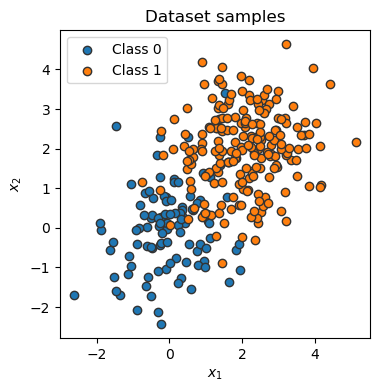

In [12]:
supervised_dataset.plot()

### The dataloader class
* supports batching
* often, we don't need a custom data loader class and just need to create an object
* communicates with the dataset instance using the function __getitem__, and stacks its outputs as tensors over the first dimension to form a batch.

In [13]:
data_loader = data.DataLoader(supervised_dataset, batch_size=8, shuffle=True)

* __batch_size__: Number of samples to stack per batch
* __shuffle__: If True, the data is returned in a random order. This is important during training for introducing stochasticity.
* __num_workers__: Number of subprocesses to use for data loading. The default, 0, means that the data will be loaded in the main process which can slow down training for datasets where loading a data point takes a considerable amount of time (e.g. large images). More workers are recommended for those, but can cause issues on Windows computers. For tiny datasets as ours, 0 workers are usually faster.
* __pin_memory__: If True, the data loader will copy Tensors into CUDA pinned memory before returning them. This can save some time for large data points on GPUs. Usually a good practice to use for a training set, but not necessarily for validation and test to save memory on the GPU.
* __drop_last__: If True, the last batch is dropped in case it is smaller than the specified batch size. This occurs when the dataset size is not a multiple of the batch size. Only potentially helpful during training to keep a consistent batch size.

In [14]:
# next(iter(...)) catches the first batch of the data loader
# If shuffle is True, this will return a different batch every time we run this cell
# For iterating over the whole dataset, we can simple use "for batch in data_loader: ..."
data_inputs, data_labels = next(iter(data_loader))

# The shape of the outputs are [batch_size, d_1,...,d_N] where d_1,...,d_N are the
# dimensions of the data point returned from the dataset class
print("Data inputs", data_inputs.shape, "\n", data_inputs)
print("Data labels", data_labels.shape, "\n", data_labels)

Data inputs torch.Size([8, 2]) 
 tensor([[ 3.8338,  2.3774],
        [-0.1021, -1.0335],
        [ 1.9665,  0.5732],
        [ 1.2674,  1.5123],
        [ 3.2359,  1.8998],
        [ 0.2469,  0.0769],
        [ 0.5885,  0.9705],
        [ 0.5229,  2.3022]])
Data labels torch.Size([8]) 
 tensor([1, 0, 1, 1, 1, 0, 1, 0], dtype=torch.int8)


## Loss function and training
### Binary cross entropy (BCE) loss

In [15]:
#Note, that this  combines a sigmoid layer and the BCE loss in a single class. 
# This is numerically more stable than nn.BCELoss(), which expects the output in the range [0,1]
loss_module = nn.BCEWithLogitsLoss()

### Optimization 
We use stochastic gradient descent.

In [16]:
# Input to the optimizer are the parameters of the model: model.parameters()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

The optimizer provides two useful functions: 
* __optimizer.step()__:  updates the parameters based on the gradients.
* __and optimizer.zero_grad()__: sets the gradients of all parameters to zero.
  + crucial pre-step before performing backpropagation.
  + otherwise, the new gradients would actually be added to the previous ones instead of overwriting them. 

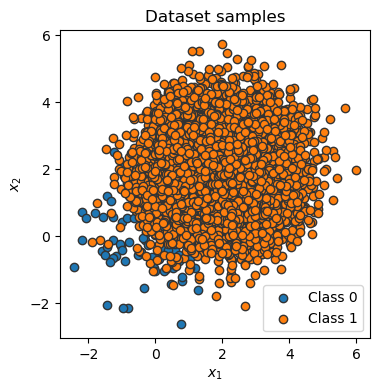

In [17]:
#a slightly larger data set
x,y = makeArtificialData(n1=100,n2=10000,d=2, sd=sd)
train_dataset = SupervisedDataset(x,y)
train_dataset.plot()
train_data_loader = data.DataLoader(train_dataset, batch_size=32, shuffle=True)

In [18]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print("Device", device)
# Push model to device. Has to be only done once. Makes only sense if you have a GPU.
model.to(device)

Device cpu


MyFirstClassifier(
  (linear1): Linear(in_features=2, out_features=4, bias=True)
  (act_fn): Tanh()
  (linear2): Linear(in_features=4, out_features=1, bias=True)
)

The following trainer function performs the following steps in a loop over batches:
1. Get a batch from the data loader
2. Obtain the predictions from the model for the batch
3. Calculate the loss based on the discrepancy between predictions and labels
4. Backpropagation: calculate the gradients for every parameter with respect to the loss
5. Update the parameters of the model in the direction of the gradients

In [19]:
def train_model(model, optimizer, data_loader, loss_module, num_epochs=100):
    # Set model to train mode. Important for certain operations (e.g. dropout)
    model.train()

    # Training loop
    for epoch in tqdm(range(num_epochs)):
        for data_inputs, data_labels in data_loader:

            ## Step 1: Move input data to device (only strictly necessary if we use GPU)
            data_inputs = data_inputs.to(device)
            data_labels = data_labels.to(device)

            ## Step 2: Run the model on the input data
            preds = model(data_inputs)
            preds = preds.squeeze(dim=1) # Output is [Batch size, 1], but we want [Batch size]

            ## Step 3: Calculate the loss
            loss = loss_module(preds, data_labels.float())

            ## Step 4: Perform backpropagation
            # Before calculating the gradients, we need to ensure that they are all zero.
            # The gradients would not be overwritten, but actually added to the existing ones.
            optimizer.zero_grad()
            # Perform backpropagation
            loss.backward()

            ## Step 5: Update the parameters
            optimizer.step()

In [20]:
train_model(model, optimizer, train_data_loader, loss_module)

  0%|          | 0/100 [00:00<?, ?it/s]

## Saving the trained model and loading a model from disk.
One can save a model to the disk. What is actually solved is a state dictionary.

In [21]:
state_dict = model.state_dict()
print(state_dict)

OrderedDict({'linear1.weight': tensor([[-0.3179, -0.5108],
        [-0.7459, -0.3905],
        [ 0.5343, -0.5278],
        [ 0.4338,  0.4683]]), 'linear1.bias': tensor([-0.9939,  1.0579,  0.1814, -0.6776]), 'linear2.weight': tensor([[-1.7040, -2.3608, -0.1998,  2.5210]]), 'linear2.bias': tensor([2.5500])})


In [22]:
# torch.save(object, filename). For the filename, any extension can be used
torch.save(state_dict, "first_model.tar")

#### Loading the model. 
We load a model from disk, create a new model from disk and load the state into 
the model. 

In [23]:
# Load state dict from the disk (make sure it is the same name as above)
state_dict = torch.load("first_model.tar")

# Create a new model and load the state
new_model = MyFirstClassifier(num_inputs=2, num_hidden=4, num_outputs=1)
new_model.load_state_dict(state_dict)

# Verify that the parameters are the same
print("Original model\n", model.state_dict())
print("\nLoaded model\n", new_model.state_dict())

Original model
 OrderedDict({'linear1.weight': tensor([[-0.3179, -0.5108],
        [-0.7459, -0.3905],
        [ 0.5343, -0.5278],
        [ 0.4338,  0.4683]]), 'linear1.bias': tensor([-0.9939,  1.0579,  0.1814, -0.6776]), 'linear2.weight': tensor([[-1.7040, -2.3608, -0.1998,  2.5210]]), 'linear2.bias': tensor([2.5500])})

Loaded model
 OrderedDict({'linear1.weight': tensor([[-0.3179, -0.5108],
        [-0.7459, -0.3905],
        [ 0.5343, -0.5278],
        [ 0.4338,  0.4683]]), 'linear1.bias': tensor([-0.9939,  1.0579,  0.1814, -0.6776]), 'linear2.weight': tensor([[-1.7040, -2.3608, -0.1998,  2.5210]]), 'linear2.bias': tensor([2.5500])})


## Evaluating the model
Fo testing, we need a test data set.

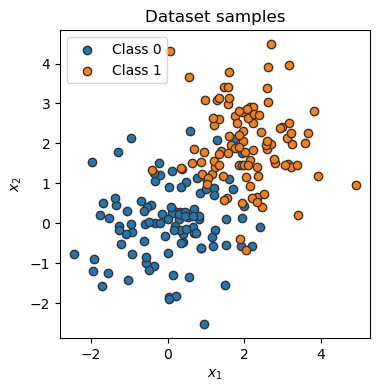

In [24]:
#a slightly smaler test data set
x,y = makeArtificialData(n1=100,n2=100,d=2, sd=sd)
test_dataset = SupervisedDataset(x,y)
test_dataset.plot()
# drop_last -> Don't drop the last batch
test_data_loader = data.DataLoader(test_dataset, batch_size=32, shuffle=False, drop_last=False)

In [25]:
def eval_model(model, data_loader):
    model.eval() # Set model to eval mode
    true_preds, num_preds = 0., 0.

    first = True
    with torch.no_grad(): # Deactivate gradients for the following code
        for data_inputs, data_labels in data_loader:
            # Determine prediction of model on dev set
            data_inputs, data_labels = data_inputs.to(device), data_labels.to(device)
            preds = model(data_inputs)
            preds = preds.squeeze(dim=1)
            preds = torch.sigmoid(preds) # Sigmoid to map predictions between 0 and 1
            if first == True:
                all_pred_proba = preds.clone()
                all_data_labels = data_labels.clone()
                first = False
            else:
                all_pred_proba = torch.cat((all_pred_proba,preds))
                all_data_labels = torch.cat((all_data_labels,data_labels))
                
            pred_labels = (preds >= 0.5).long() # Binarize predictions to 0 and 1

            # Keep records of predictions for the accuracy metric (true_preds=TP+TN, num_preds=TP+TN+FP+FN)
            true_preds += (pred_labels == data_labels).sum()
            num_preds += data_labels.shape[0]

    acc = true_preds / num_preds
    print(f"Accuracy of the model: {100.0*acc:4.2f}%")
    return(all_pred_proba,all_data_labels)

In [26]:
all_preds_proba, all_data_labels = eval_model(new_model, test_data_loader)
all_preds_proba = all_preds_proba.cpu().numpy()
all_data_labels = all_data_labels.cpu().numpy()

Accuracy of the model: 67.00%


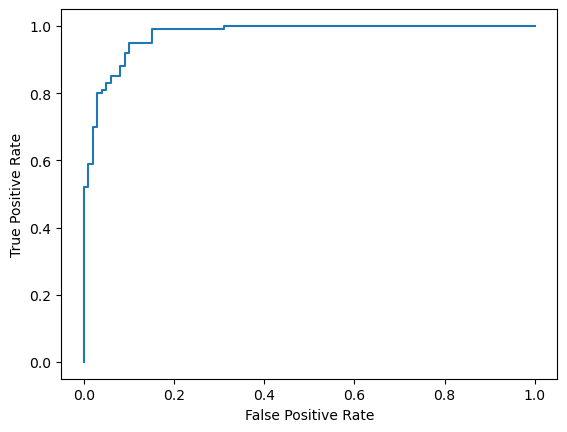

AUC= 0.9733999999999999


In [27]:
#compute the fals positive rate and the false negative rate
fpr, tpr, _ = metrics.roc_curve(all_data_labels, all_preds_proba)

#create ROC curve
plt.plot(fpr,tpr)
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

auc = metrics.roc_auc_score(all_data_labels, all_preds_proba)
print('AUC=',auc)